In [ ]:

# STEP 1: Install the Python libraries we need

!pip -q install pandas numpy matplotlib seaborn openpyxl rapidfuzz scipy

# STEP 2: Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from datetime import datetime
from rapidfuzz import fuzz
from scipy import stats

# STEP 3: Create folders for our project

folders = [
    "aldar_audit_project/data/raw",
    "aldar_audit_project/data/processed",
    "aldar_audit_project/outputs/charts",
    "aldar_audit_project/outputs/reports",
    "aldar_audit_project/outputs/exceptions"
]

for folder in folders:
    os.makedirs(folder, exist_ok=True)

# STEP 4: Confirm that everything is ready

print("Aldar Audit Analytics environment ready!")
print("All project folders created successfully.")

Aldar Audit Analytics environment ready!
All project folders created successfully.


In [ ]:

# CELL 2: Aldar's published financial data

import pandas as pd

financial_data = {
    "Metric": [
        "Revenue and rental income",
        "Direct costs",
        "Gross profit",
        "Profit for the year",
        "Contract assets",
        "Contract liabilities",
        "Advances from customers"
    ],

    "2025_AED_million": [
        33818.316,
        22242.992,
        11575.324,
        8833.581,
        9241.204,
        9848.387,
        1002.405
    ],

    "2024_AED_million": [
        22998.382,
        14953.241,
        8045.141,
        6503.939,
        4448.822,
        7656.148,
        814.990
    ]
}

# Convert the information into a table

aldar_financials = pd.DataFrame(financial_data)

# Calculate percentage change between 2024 and 2025

aldar_financials["Change_%"] = (
    (aldar_financials["2025_AED_million"] /
     aldar_financials["2024_AED_million"]) - 1
) * 100

# Display the final table

aldar_financials.round(2)

,Metric,2025_AED_million,2024_AED_million,Change_%
0,Revenue and rental income,33818.32,22998.38,47.05
1,Direct costs,22242.99,14953.24,48.75
2,Gross profit,11575.32,8045.14,43.88
3,Profit for the year,8833.58,6503.94,35.82
4,Contract assets,9241.20,4448.82,107.72
5,Contract liabilities,9848.39,7656.15,28.63
6,Advances from customers,1002.40,814.99,23.00


In [ ]:

# CELL 3: Create a sample property sales dataset

import pandas as pd

transactions = {
    "transaction_id": [
        "TR001", "TR002", "TR003", "TR004", "TR005",
        "TR006", "TR007", "TR008", "TR009", "TR010"
    ],

    "contract_id": [
        "C101", "C102", "C103", "C104", "C105",
        "C106", "C107", "C108", "C109", "C110"
    ],

    "project_id": [
        "ALDAR_A", "ALDAR_A", "ALDAR_B", "ALDAR_B", "ALDAR_C",
        "ALDAR_C", "ALDAR_A", "ALDAR_B", "ALDAR_C", "ALDAR_A"
    ],

    "posting_date": [
        "2025-03-15", "2025-06-20", "2025-09-10",
        "2025-12-28", "2025-12-31", "2026-01-05",
        "2025-11-15", "2025-12-30", "2025-12-31",
        "2025-12-31"
    ],

    "invoice_date": [
        "2025-03-14", "2025-06-19", "2025-09-09",
        "2025-12-27", "2025-12-30", "2025-12-30",
        "2025-11-14", "2025-12-29", "2025-12-30",
        "2025-12-30"
    ],

    "transaction_amount_AED": [
        450000, 750000, 1200000, 950000, 2500000,
        1800000, 650000, 3000000, 5000000, 10000000
    ],

    "recognition_method": [
        "Point in time", "Over time", "Over time",
        "Point in time", "Point in time", "Over time",
        "Over time", "Point in time", "Over time", "Point in time"
    ],

    "progress_pct": [
        100, 45, 70, 100, 100, 35, 60, 100, 110, 100
    ],

    "performance_obligation_status": [
        "Satisfied", "In progress", "In progress",
        "Satisfied", "Satisfied", "In progress",
        "In progress", "Satisfied", "In progress", "Satisfied"
    ],

    "user_id": [
        "USER01", "USER02", "USER01", "USER03", "USER04",
        "USER02", "USER01", "USER03", "USER04", "USER05"
    ]
}

audit_data = pd.DataFrame(transactions)

# Convert date columns into proper date format

audit_data["posting_date"] = pd.to_datetime(audit_data["posting_date"])
audit_data["invoice_date"] = pd.to_datetime(audit_data["invoice_date"])

# Display the dataset

audit_data

,transaction_id,contract_id,project_id,posting_date,invoice_date,transaction_amount_AED,recognition_method,progress_pct,performance_obligation_status,user_id
0,TR001,C101,ALDAR_A,2025-03-15,2025-03-14,450000,Point in time,100,Satisfied,USER01
1,TR002,C102,ALDAR_A,2025-06-20,2025-06-19,750000,Over time,45,In progress,USER02
2,TR003,C103,ALDAR_B,2025-09-10,2025-09-09,1200000,Over time,70,In progress,USER01
3,TR004,C104,ALDAR_B,2025-12-28,2025-12-27,950000,Point in time,100,Satisfied,USER03
4,TR005,C105,ALDAR_C,2025-12-31,2025-12-30,2500000,Point in time,100,Satisfied,USER04
5,TR006,C106,ALDAR_C,2026-01-05,2025-12-30,1800000,Over time,35,In progress,USER02
6,TR007,C107,ALDAR_A,2025-11-15,2025-11-14,650000,Over time,60,In progress,USER01
7,TR008,C108,ALDAR_B,2025-12-30,2025-12-29,3000000,Point in time,100,Satisfied,USER03
8,TR009,C109,ALDAR_C,2025-12-31,2025-12-30,5000000,Over time,110,In progress,USER04
9,TR010,C110,ALDAR_A,2025-12-31,2025-12-30,10000000,Point in time,100,Satisfied,USER05


In [ ]:

# CELL 4: Initial audit exception tests

# Test 1: Identify progress greater than 100%

audit_data["Progress_Exception"] = (
    audit_data["progress_pct"] > 100
)

# Test 2: Identify invoices dated in 2025
# but posted after the 2025 financial year-end

audit_data["Cutoff_Exception"] = (
    (audit_data["invoice_date"].dt.year == 2025) &
    (audit_data["posting_date"].dt.year > 2025)
)

# Test 3: Identify transactions posted
# during the final three days of 2025

audit_data["Year_End_Exception"] = (
    (audit_data["posting_date"] >= "2025-12-29") &
    (audit_data["posting_date"] <= "2025-12-31")
)

# Combine all three tests

audit_data["Total_Exceptions"] = (
    audit_data["Progress_Exception"].astype(int) +
    audit_data["Cutoff_Exception"].astype(int) +
    audit_data["Year_End_Exception"].astype(int)
)

# Display transactions with potential exceptions

exceptions = audit_data[
    audit_data["Total_Exceptions"] > 0
]

exceptions

,transaction_id,contract_id,project_id,posting_date,invoice_date,transaction_amount_AED,recognition_method,progress_pct,performance_obligation_status,user_id,Progress_Exception,Cutoff_Exception,Year_End_Exception,Total_Exceptions
4,TR005,C105,ALDAR_C,2025-12-31,2025-12-30,2500000,Point in time,100,Satisfied,USER04,False,False,True,1
5,TR006,C106,ALDAR_C,2026-01-05,2025-12-30,1800000,Over time,35,In progress,USER02,False,True,False,1
7,TR008,C108,ALDAR_B,2025-12-30,2025-12-29,3000000,Point in time,100,Satisfied,USER03,False,False,True,1
8,TR009,C109,ALDAR_C,2025-12-31,2025-12-30,5000000,Over time,110,In progress,USER04,True,False,True,2
9,TR010,C110,ALDAR_A,2025-12-31,2025-12-30,10000000,Point in time,100,Satisfied,USER05,False,False,True,1


In [ ]:

# CELL 5: Audit exception summary

# Count transactions flagged by each test

exception_summary = pd.DataFrame({
    "Exception_Type": [
        "Progress above 100%",
        "Invoice posted after year-end",
        "Posted in final 3 days of 2025"
    ],

    "Number_of_Transactions": [
        audit_data["Progress_Exception"].sum(),
        audit_data["Cutoff_Exception"].sum(),
        audit_data["Year_End_Exception"].sum()
    ],

    "Total_Amount_AED": [
        audit_data.loc[
            audit_data["Progress_Exception"],
            "transaction_amount_AED"
        ].sum(),

        audit_data.loc[
            audit_data["Cutoff_Exception"],
            "transaction_amount_AED"
        ].sum(),

        audit_data.loc[
            audit_data["Year_End_Exception"],
            "transaction_amount_AED"
        ].sum()
    ]
})

exception_summary

,Exception_Type,Number_of_Transactions,Total_Amount_AED
0,Progress above 100%,1,5000000
1,Invoice posted after year-end,1,1800000
2,Posted in final 3 days of 2025,4,20500000


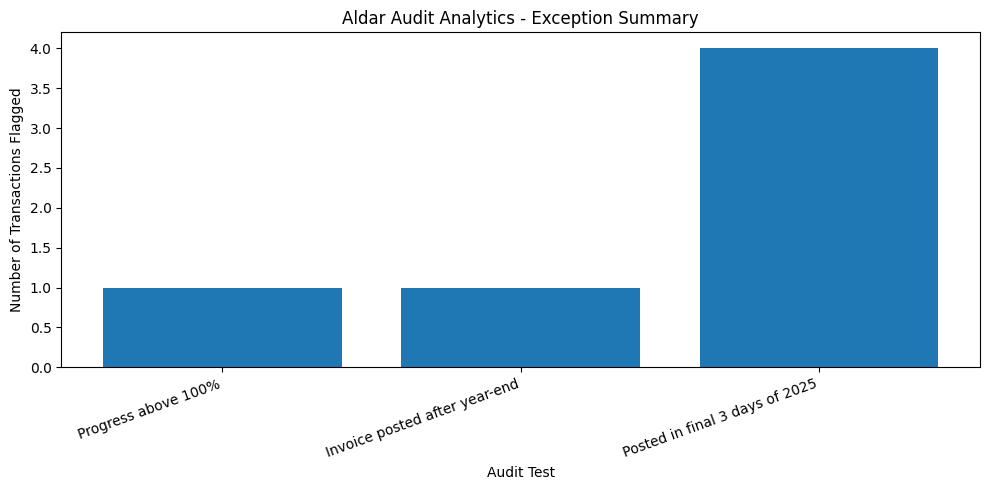

In [ ]:

# CELL 6: Visualise audit exceptions

plt.figure(figsize=(10, 5))

plt.bar(
    exception_summary["Exception_Type"],
    exception_summary["Number_of_Transactions"]
)

plt.title("Aldar Audit Analytics - Exception Summary")
plt.xlabel("Audit Test")
plt.ylabel("Number of Transactions Flagged")

plt.xticks(rotation=20, ha="right")

plt.tight_layout()
plt.show()

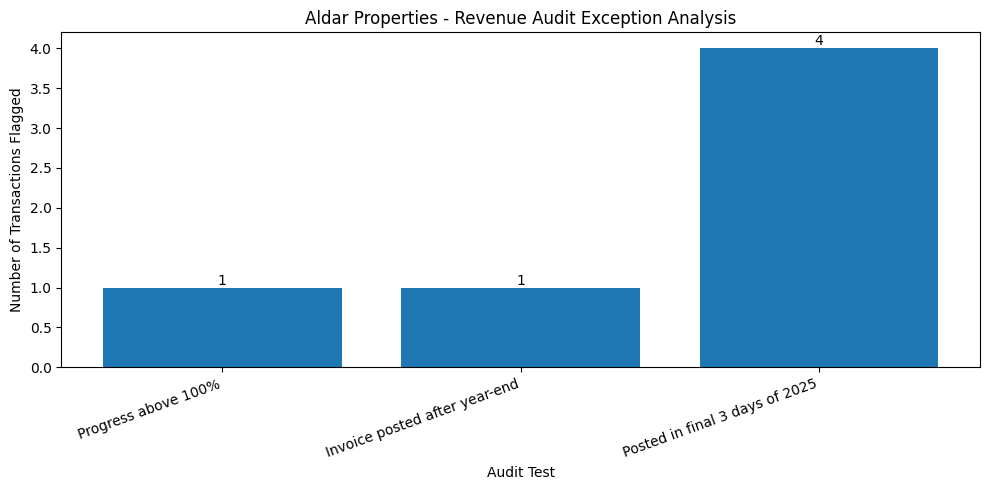

In [ ]:

# CELL 7: Improved audit exception chart

plt.figure(figsize=(10, 5))

bars = plt.bar(
    exception_summary["Exception_Type"],
    exception_summary["Number_of_Transactions"]
)

plt.title("Aldar Properties - Revenue Audit Exception Analysis")
plt.xlabel("Audit Test")
plt.ylabel("Number of Transactions Flagged")

plt.xticks(rotation=20, ha="right")

# Display numbers above each bar

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(
    "aldar_audit_project/outputs/charts/exception_summary.png",
    dpi=300
)
plt.show()

In [ ]:

# CELL 8: Add a simulated duplicate transaction

# Create a duplicate of transaction TR003

duplicate_transaction = audit_data[
    audit_data["transaction_id"] == "TR003"
].copy()

# Give it a new transaction ID, but retain the same
# contract, invoice date and amount

duplicate_transaction["transaction_id"] = "TR011"

# Add the duplicate to our dataset

audit_data = pd.concat(
    [audit_data, duplicate_transaction],
    ignore_index=True
)

print("New transaction added.")
print("Total transactions:", len(audit_data))

# Identify possible duplicates using contract,
# invoice date and transaction amount

audit_data["Duplicate_Flag"] = audit_data.duplicated(
    subset=[
        "contract_id",
        "invoice_date",
        "transaction_amount_AED"
    ],
    keep=False
)

# Display possible duplicate transactions

duplicates = audit_data[
    audit_data["Duplicate_Flag"] == True
]

duplicates

New transaction added.
Total transactions: 11


,transaction_id,contract_id,project_id,posting_date,invoice_date,transaction_amount_AED,recognition_method,progress_pct,performance_obligation_status,user_id,Progress_Exception,Cutoff_Exception,Year_End_Exception,Total_Exceptions,Duplicate_Flag
2,TR003,C103,ALDAR_B,2025-09-10,2025-09-09,1200000,Over time,70,In progress,USER01,False,False,False,0,True
10,TR011,C103,ALDAR_B,2025-09-10,2025-09-09,1200000,Over time,70,In progress,USER01,False,False,False,0,True


In [ ]:

# CELL 9: Duplicate transaction summary

duplicate_summary = duplicates[
    [
        "transaction_id",
        "contract_id",
        "invoice_date",
        "transaction_amount_AED"
    ]
].copy()

print("POTENTIAL DUPLICATE TRANSACTIONS")
display(duplicate_summary)

print("Number of flagged records:", len(duplicates))

print(
    "Combined value of flagged records (AED):",
    duplicates["transaction_amount_AED"].sum()
)

print(
    "Potential duplicate amount (AED):",
    duplicates["transaction_amount_AED"].max()
)

POTENTIAL DUPLICATE TRANSACTIONS


,transaction_id,contract_id,invoice_date,transaction_amount_AED
2,TR003,C103,2025-09-09,1200000
10,TR011,C103,2025-09-09,1200000


Number of flagged records: 2
Combined value of flagged records (AED): 2400000
Potential duplicate amount (AED): 1200000


In [ ]:


# CELL 10: Analyse transaction values by user

user_analysis = (
    audit_data.groupby("user_id")
    .agg(
        Number_of_Transactions=("transaction_id", "count"),
        Total_Transaction_Value=("transaction_amount_AED", "sum"),
        Average_Transaction_Value=("transaction_amount_AED", "mean"),
        Highest_Transaction_Value=("transaction_amount_AED", "max")
    )
    .reset_index()
)

# Round average values for readability

user_analysis["Average_Transaction_Value"] = (
    user_analysis["Average_Transaction_Value"].round(2)
)

# Display results

user_analysis.sort_values(
    by="Total_Transaction_Value",
    ascending=False
)

,user_id,Number_of_Transactions,Total_Transaction_Value,Average_Transaction_Value,Highest_Transaction_Value
4,USER05,1,10000000,10000000.0,10000000
3,USER04,2,7500000,3750000.0,5000000
2,USER03,2,3950000,1975000.0,3000000
0,USER01,4,3500000,875000.0,1200000
1,USER02,2,2550000,1275000.0,1800000


In [ ]:

# CELL 11: Identify large transactions

large_transaction_threshold = 5000000

audit_data["Large_Transaction_Flag"] = (
    audit_data["transaction_amount_AED"]
    >= large_transaction_threshold
)

# Extract flagged transactions

large_transactions = audit_data[
    audit_data["Large_Transaction_Flag"]
].copy()

# Display results

print("LARGE TRANSACTIONS REQUIRING REVIEW")

display(
    large_transactions[
        [
            "transaction_id",
            "contract_id",
            "user_id",
            "transaction_amount_AED",
            "posting_date"
        ]
    ]
)

print(
    "Number of large transactions:",
    len(large_transactions)
)

print(
    "Total value (AED):",
    large_transactions["transaction_amount_AED"].sum()
)

LARGE TRANSACTIONS REQUIRING REVIEW


,transaction_id,contract_id,user_id,transaction_amount_AED,posting_date
8,TR009,C109,USER04,5000000,2025-12-31
9,TR010,C110,USER05,10000000,2025-12-31


Number of large transactions: 2
Total value (AED): 15000000


In [ ]:

# CELL 12: Identify round-number transactions

audit_data["Round_Number_Flag"] = (
    audit_data["transaction_amount_AED"] % 100000 == 0
)

round_transactions = audit_data[
    audit_data["Round_Number_Flag"]
].copy()

print("ROUND-NUMBER TRANSACTIONS")

display(
    round_transactions[
        [
            "transaction_id",
            "user_id",
            "transaction_amount_AED",
            "posting_date"
        ]
    ]
)

print(
    "Number of round-number transactions:",
    len(round_transactions)
)

ROUND-NUMBER TRANSACTIONS


,transaction_id,user_id,transaction_amount_AED,posting_date
2,TR003,USER01,1200000,2025-09-10
4,TR005,USER04,2500000,2025-12-31
5,TR006,USER02,1800000,2026-01-05
7,TR008,USER03,3000000,2025-12-30
8,TR009,USER04,5000000,2025-12-31
9,TR010,USER05,10000000,2025-12-31
10,TR011,USER01,1200000,2025-09-10


Number of round-number transactions: 7


In [ ]:

# CELL 13: Combine audit risk indicators

risk_columns = [
    "Progress_Exception",
    "Cutoff_Exception",
    "Year_End_Exception",
    "Duplicate_Flag",
    "Large_Transaction_Flag",
    "Round_Number_Flag"
]

# Count how many tests flag each transaction

audit_data["Risk_Indicator_Count"] = (
    audit_data[risk_columns].sum(axis=1)
)

# Display transactions with at least one indicator

risk_register = audit_data[
    audit_data["Risk_Indicator_Count"] > 0
].copy()

risk_register = risk_register.sort_values(
    by="Risk_Indicator_Count",
    ascending=False
)

display(
    risk_register[
        [
            "transaction_id",
            "transaction_amount_AED",
            "user_id",
            "Risk_Indicator_Count"
        ]
    ]
)

,transaction_id,transaction_amount_AED,user_id,Risk_Indicator_Count
8,TR009,5000000,USER04,4
9,TR010,10000000,USER05,3
2,TR003,1200000,USER01,2
5,TR006,1800000,USER02,2
4,TR005,2500000,USER04,2
7,TR008,3000000,USER03,2
10,TR011,1200000,USER01,2


In [ ]:

# CELL 14: Generate a larger synthetic transaction dataset

np.random.seed(42)

number_of_transactions = 500

large_data = pd.DataFrame({
    "transaction_id": [
        f"TR{i:04d}" for i in range(1, number_of_transactions + 1)
    ],
    "contract_id": [
        f"C{np.random.randint(100, 250)}"
        for _ in range(number_of_transactions)
    ],
    "project_id": np.random.choice(
        ["ALDAR_A", "ALDAR_B", "ALDAR_C", "ALDAR_D"],
        number_of_transactions
    ),
    "posting_date": pd.to_datetime(
        np.random.choice(
            pd.date_range("2025-01-01", "2026-01-15"),
            number_of_transactions
        )
    ),
    "transaction_amount_AED": np.random.randint(
        50000, 5000000, number_of_transactions
    ),
    "recognition_method": np.random.choice(
        ["Point in time", "Over time"],
        number_of_transactions
    ),
    "progress_pct": np.random.randint(
        0, 101, number_of_transactions
    ),
    "user_id": np.random.choice(
        ["USER01", "USER02", "USER03", "USER04", "USER05"],
        number_of_transactions
    )
})

# Add deliberately planted training scenarios

large_data.loc[0, "progress_pct"] = 115
large_data.loc[1, "transaction_amount_AED"] = 10000000
large_data.loc[2, "posting_date"] = pd.Timestamp("2025-12-31")
large_data.loc[3, "posting_date"] = pd.Timestamp("2025-12-30")
large_data.loc[4, "posting_date"] = pd.Timestamp("2026-01-05")

print("Synthetic dataset created successfully!")
print("Number of transactions:", len(large_data))

display(large_data.head(10))

Synthetic dataset created successfully!
Number of transactions: 500


,transaction_id,contract_id,project_id,posting_date,transaction_amount_AED,recognition_method,progress_pct,user_id
0,TR0001,C202,ALDAR_D,2025-07-31,4018222,Over time,115,USER04
1,TR0002,C192,ALDAR_D,2025-08-13,10000000,Point in time,53,USER03
2,TR0003,C114,ALDAR_A,2025-12-31,888003,Over time,51,USER04
3,TR0004,C206,ALDAR_A,2025-12-30,3483382,Over time,2,USER02
4,TR0005,C171,ALDAR_B,2026-01-05,331570,Point in time,98,USER02
5,TR0006,C120,ALDAR_D,2025-02-16,3232993,Point in time,40,USER03
6,TR0007,C202,ALDAR_A,2025-01-01,4131082,Point in time,5,USER01
7,TR0008,C221,ALDAR_C,2025-03-31,3445049,Over time,24,USER05
8,TR0009,C174,ALDAR_C,2025-05-22,116150,Point in time,12,USER04
9,TR0010,C187,ALDAR_A,2025-11-16,2484206,Over time,97,USER02


In [ ]:

# CELL 15: Add fields needed for audit testing

# Create invoice dates, usually shortly before posting dates
large_data["invoice_date"] = (
    large_data["posting_date"] -
    pd.to_timedelta(
        np.random.randint(0, 8, len(large_data)),
        unit="D"
    )
)

# Create fictional journal entry references
large_data["journal_id"] = [
    f"JE{i:04d}" for i in range(1, len(large_data) + 1)
]

# Add performance obligation status
large_data["performance_obligation_status"] = np.where(
    large_data["progress_pct"] >= 100,
    "Satisfied",
    "In progress"
)

# Label the data source clearly
large_data["data_source"] = "Simulated"

# Display the updated dataset
display(large_data.head(10))

print("Total transactions:", len(large_data))
print("Total columns:", len(large_data.columns))

,transaction_id,contract_id,project_id,posting_date,transaction_amount_AED,recognition_method,progress_pct,user_id,invoice_date,journal_id,performance_obligation_status,data_source
0,TR0001,C202,ALDAR_D,2025-07-31,4018222,Over time,115,USER04,2025-07-25,JE0001,Satisfied,Simulated
1,TR0002,C192,ALDAR_D,2025-08-13,10000000,Point in time,53,USER03,2025-08-07,JE0002,In progress,Simulated
2,TR0003,C114,ALDAR_A,2025-12-31,888003,Over time,51,USER04,2025-12-29,JE0003,In progress,Simulated
3,TR0004,C206,ALDAR_A,2025-12-30,3483382,Over time,2,USER02,2025-12-25,JE0004,In progress,Simulated
4,TR0005,C171,ALDAR_B,2026-01-05,331570,Point in time,98,USER02,2026-01-03,JE0005,In progress,Simulated
5,TR0006,C120,ALDAR_D,2025-02-16,3232993,Point in time,40,USER03,2025-02-16,JE0006,In progress,Simulated
6,TR0007,C202,ALDAR_A,2025-01-01,4131082,Point in time,5,USER01,2025-01-01,JE0007,In progress,Simulated
7,TR0008,C221,ALDAR_C,2025-03-31,3445049,Over time,24,USER05,2025-03-26,JE0008,In progress,Simulated
8,TR0009,C174,ALDAR_C,2025-05-22,116150,Point in time,12,USER04,2025-05-15,JE0009,In progress,Simulated
9,TR0010,C187,ALDAR_A,2025-11-16,2484206,Over time,97,USER02,2025-11-12,JE0010,In progress,Simulated


Total transactions: 500
Total columns: 12


In [ ]:

# CELL 16: Audit tests on 500 transactions

# Test 1: Progress above 100%
large_data["Progress_Exception"] = (
    large_data["progress_pct"] > 100
)

# Test 2: Invoice in 2025 but posted after year-end
large_data["Cutoff_Exception"] = (
    (large_data["invoice_date"].dt.year == 2025) &
    (large_data["posting_date"].dt.year > 2025)
)

# Test 3: Posted during final three days of 2025
large_data["Year_End_Exception"] = (
    (large_data["posting_date"] >= "2025-12-29") &
    (large_data["posting_date"] <= "2025-12-31")
)

# Test 4: Large transactions
large_data["Large_Transaction_Flag"] = (
    large_data["transaction_amount_AED"] >= 5000000
)

# Test 5: Round-number transactions
large_data["Round_Number_Flag"] = (
    large_data["transaction_amount_AED"] % 100000 == 0
)

# Count the number of tests triggered
risk_columns = [
    "Progress_Exception",
    "Cutoff_Exception",
    "Year_End_Exception",
    "Large_Transaction_Flag",
    "Round_Number_Flag"
]

large_data["Risk_Indicator_Count"] = (
    large_data[risk_columns].sum(axis=1)
)

# Display the results
print("AUDIT TESTING COMPLETED")
print("Total transactions:", len(large_data))
print("Transactions with at least one indicator:",
      (large_data["Risk_Indicator_Count"] > 0).sum())

display(
    large_data[
        large_data["Risk_Indicator_Count"] > 0
    ].head(20)
)

AUDIT TESTING COMPLETED
Total transactions: 500
Transactions with at least one indicator: 14


,transaction_id,contract_id,project_id,posting_date,transaction_amount_AED,recognition_method,progress_pct,user_id,invoice_date,journal_id,performance_obligation_status,data_source,Progress_Exception,Cutoff_Exception,Year_End_Exception,Large_Transaction_Flag,Round_Number_Flag,Risk_Indicator_Count
0,TR0001,C202,ALDAR_D,2025-07-31,4018222,Over time,115,USER04,2025-07-25,JE0001,Satisfied,Simulated,True,False,False,False,False,1
1,TR0002,C192,ALDAR_D,2025-08-13,10000000,Point in time,53,USER03,2025-08-07,JE0002,In progress,Simulated,False,False,False,True,True,2
2,TR0003,C114,ALDAR_A,2025-12-31,888003,Over time,51,USER04,2025-12-29,JE0003,In progress,Simulated,False,False,True,False,False,1
3,TR0004,C206,ALDAR_A,2025-12-30,3483382,Over time,2,USER02,2025-12-25,JE0004,In progress,Simulated,False,False,True,False,False,1
118,TR0119,C242,ALDAR_C,2025-12-31,3039179,Point in time,51,USER04,2025-12-27,JE0119,In progress,Simulated,False,False,True,False,False,1
151,TR0152,C212,ALDAR_A,2025-12-29,3329269,Point in time,7,USER01,2025-12-25,JE0152,In progress,Simulated,False,False,True,False,False,1
206,TR0207,C159,ALDAR_B,2025-12-30,3484955,Point in time,7,USER02,2025-12-28,JE0207,In progress,Simulated,False,False,True,False,False,1
268,TR0269,C216,ALDAR_A,2026-01-01,4047615,Over time,22,USER01,2025-12-29,JE0269,In progress,Simulated,False,True,False,False,False,1
331,TR0332,C152,ALDAR_B,2025-12-30,1197087,Over time,85,USER04,2025-12-27,JE0332,In progress,Simulated,False,False,True,False,False,1
342,TR0343,C154,ALDAR_B,2026-01-05,4385702,Over time,74,USER02,2025-12-31,JE0343,In progress,Simulated,False,True,False,False,False,1


In [ ]:
# CELL 17: AUDIT EXCEPTION SUMMARY

exception_columns = {
    "Progress above 100%": "Progress_Exception",
    "Invoice posted after year-end": "Cutoff_Exception",
    "Posted in final 3 days of 2025": "Year_End_Exception",
    "Large transactions (AED 5m+)": "Large_Transaction_Flag",
    "Round-number transactions": "Round_Number_Flag"
}

summary_results = []

for test_name, column_name in exception_columns.items():

    flagged = large_data[large_data[column_name] == True]

    summary_results.append({
        "Audit Test": test_name,
        "Transactions Flagged": len(flagged),
        "Total Value (AED)": flagged["transaction_amount_AED"].sum()
    })

exception_summary = pd.DataFrame(summary_results)

print("AUDIT EXCEPTION SUMMARY")
display(exception_summary)

AUDIT EXCEPTION SUMMARY


,Audit Test,Transactions Flagged,Total Value (AED)
0,Progress above 100%,1,4018222
1,Invoice posted after year-end,3,12689736
2,Posted in final 3 days of 2025,9,25796648
3,Large transactions (AED 5m+),1,10000000
4,Round-number transactions,1,10000000


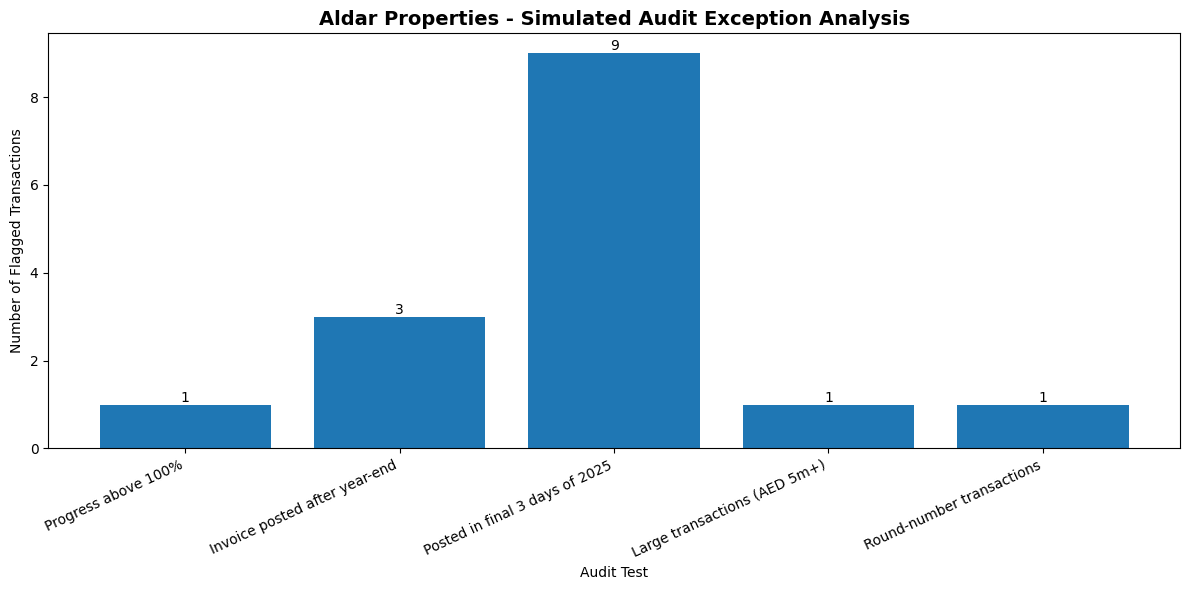

In [ ]:
# CELL 18: AUDIT EXCEPTION CHART

plt.figure(figsize=(12, 6))

bars = plt.bar(
    exception_summary["Audit Test"],
    exception_summary["Transactions Flagged"]
)

plt.title(
    "Aldar Properties - Simulated Audit Exception Analysis",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Audit Test")
plt.ylabel("Number of Flagged Transactions")

plt.xticks(rotation=25, ha="right")

# Display values above each bar
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        str(int(height)),
        ha="center",
        va="bottom"
    )

plt.tight_layout()

plt.savefig(
    "aldar_audit_project/outputs/charts/audit_exception_summary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
# CELL 19: CREATE A SIMULATED DUPLICATE

# Select an existing transaction
duplicate_record = large_data.iloc[[10]].copy()

# Give the copied transaction a new transaction ID
duplicate_record["transaction_id"] = "TR0501"

# Give it a new journal ID
duplicate_record["journal_id"] = "JE0501"

# Add the copied record to the dataset
large_data = pd.concat(
    [large_data, duplicate_record],
    ignore_index=True
)

print("Duplicate training scenario added.")
print("Total transactions:", len(large_data))

display(large_data.tail(2))

Duplicate training scenario added.
Total transactions: 501


,transaction_id,contract_id,project_id,posting_date,transaction_amount_AED,recognition_method,progress_pct,user_id,invoice_date,journal_id,performance_obligation_status,data_source,Progress_Exception,Cutoff_Exception,Year_End_Exception,Large_Transaction_Flag,Round_Number_Flag,Risk_Indicator_Count
499,TR0500,C182,ALDAR_C,2025-03-23,2977337,Over time,44,USER03,2025-03-22,JE0500,In progress,Simulated,False,False,False,False,False,0
500,TR0501,C216,ALDAR_A,2025-02-07,609723,Over time,7,USER01,2025-01-31,JE0501,In progress,Simulated,False,False,False,False,False,0


In [ ]:
# CELL 20: DUPLICATE TRANSACTION DETECTION

duplicate_columns = [
    "contract_id",
    "invoice_date",
    "transaction_amount_AED"
]

large_data["Duplicate_Flag"] = large_data.duplicated(
    subset=duplicate_columns,
    keep=False
)

duplicate_transactions = large_data[
    large_data["Duplicate_Flag"] == True
].sort_values(by=duplicate_columns)

print("DUPLICATE TRANSACTION TEST")
print("Records flagged:", len(duplicate_transactions))

display(
    duplicate_transactions[
        [
            "transaction_id",
            "contract_id",
            "invoice_date",
            "transaction_amount_AED",
            "journal_id",
            "Duplicate_Flag"
        ]
    ]
)

DUPLICATE TRANSACTION TEST
Records flagged: 2


,transaction_id,contract_id,invoice_date,transaction_amount_AED,journal_id,Duplicate_Flag
10,TR0011,C216,2025-01-31,609723,JE0011,True
500,TR0501,C216,2025-01-31,609723,JE0501,True


In [ ]:
# CELL 21: COMBINED AUDIT RISK ANALYSIS

risk_columns = [
    "Progress_Exception",
    "Cutoff_Exception",
    "Year_End_Exception",
    "Large_Transaction_Flag",
    "Round_Number_Flag",
    "Duplicate_Flag"
]

# Recalculate risk indicator count, including duplicate flags
large_data["Risk_Indicator_Count"] = (
    large_data[risk_columns].sum(axis=1)
)

# Select transactions with at least one risk indicator
audit_findings = large_data[
    large_data["Risk_Indicator_Count"] > 0
].copy()

# Sort highest risk indicator count first
audit_findings = audit_findings.sort_values(
    by=["Risk_Indicator_Count", "transaction_amount_AED"],
    ascending=[False, False]
)

print("COMBINED AUDIT FINDINGS")
print("Total flagged records:", len(audit_findings))

display(
    audit_findings[
        [
            "transaction_id",
            "contract_id",
            "transaction_amount_AED",
            "user_id",
            "Risk_Indicator_Count",
            "Duplicate_Flag"
        ]
    ]
)

COMBINED AUDIT FINDINGS
Total flagged records: 16


,transaction_id,contract_id,transaction_amount_AED,user_id,Risk_Indicator_Count,Duplicate_Flag
1,TR0002,C192,10000000,USER03,2,False
431,TR0432,C214,4650108,USER05,1,False
397,TR0398,C237,4493778,USER05,1,False
342,TR0343,C154,4385702,USER02,1,False
494,TR0495,C236,4256419,USER02,1,False
268,TR0269,C216,4047615,USER01,1,False
0,TR0001,C202,4018222,USER04,1,False
206,TR0207,C159,3484955,USER02,1,False
3,TR0004,C206,3483382,USER02,1,False
151,TR0152,C212,3329269,USER01,1,False


In [ ]:
# CELL 22: EXPORT AUDIT RESULTS TO EXCEL

excel_path = (
    "aldar_audit_project/outputs/reports/"
    "Aldar_Audit_Analytics_Results.xlsx"
)

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    aldar_financials.to_excel(
        writer, sheet_name="Published Financials", index=False
    )

    large_data.to_excel(
        writer, sheet_name="Simulated Transactions", index=False
    )

    exception_summary.to_excel(
        writer, sheet_name="Exception Summary", index=False
    )

    audit_findings.to_excel(
        writer, sheet_name="Combined Findings", index=False
    )

    duplicate_transactions.to_excel(
        writer, sheet_name="Potential Duplicates", index=False
    )

print("EXCEL REPORT CREATED SUCCESSFULLY")
print(excel_path)

EXCEL REPORT CREATED SUCCESSFULLY
aldar_audit_project/outputs/reports/Aldar_Audit_Analytics_Results.xlsx


In [ ]:
# CELL 23: GENERATE PROJECT SUMMARY REPORT

report = f"""
ALDAR PROPERTIES PJSC
REVENUE AND JOURNAL ENTRY AUDIT ANALYTICS

PROJECT OVERVIEW
----------------
This project demonstrates the use of Python for financial
data analysis and simulated audit testing.

COMPANY
-------
Aldar Properties PJSC

FINANCIAL DATA
--------------
Published financial information was taken from Aldar's
2025 Annual Report, including 2024 comparative figures.

TRANSACTION DATA
----------------
The transaction-level dataset contains simulated training
records. It is not Aldar's actual accounting ledger.

DATASET SIZE
------------
Total simulated transactions: {len(large_data)}

AUDIT TEST RESULTS
------------------
Records with at least one risk indicator: {len(audit_findings)}

Potential duplicate records: {len(duplicate_transactions)}

AUDIT TESTS PERFORMED
---------------------
1. Progress percentage above 100%
2. Invoice posted after year-end
3. Transactions posted in the final three days of 2025
4. Large transaction testing
5. Round-number transaction testing
6. Potential duplicate transaction testing

FINANCIAL OBSERVATION
---------------------
Aldar's published revenue and rental income increased
from AED 22,998.382 million in 2024 to
AED 33,818.316 million in 2025.

Published contract assets increased from
AED 4,448.822 million in 2024 to
AED 9,241.204 million in 2025.

These movements provide context for further analysis.
They do not, by themselves, indicate an accounting error.

IMPORTANT LIMITATIONS
---------------------
The transaction-level dataset is simulated.
Risk indicators are not confirmed audit misstatements.
Further investigation would require contracts, invoices,
handover evidence, journal approvals and other supporting
documentation.

This is an educational portfolio project, not an actual
audit of Aldar Properties PJSC and not an audit opinion.

TOOLS USED
----------
Python, Google Colab, Pandas, NumPy, Matplotlib,
Seaborn and Excel.

END OF REPORT
"""

report_path = (
    "aldar_audit_project/outputs/reports/"
    "Aldar_Audit_Project_Summary.txt"
)

with open(report_path, "w") as file:
    file.write(report)

print("PROJECT SUMMARY REPORT CREATED!")
print(report_path)

PROJECT SUMMARY REPORT CREATED!
aldar_audit_project/outputs/reports/Aldar_Audit_Project_Summary.txt


In [ ]:
requirements = """
pandas
numpy
matplotlib
seaborn
openpyxl
rapidfuzz
scipy
"""

with open(
    "aldar_audit_project/requirements.txt", "w"
) as file:
    file.write(requirements.strip())

print("Requirements file created successfully!")

Requirements file created successfully!


In [ ]:
large_data.to_csv(
    "aldar_audit_project/data/processed/simulated_transactions.csv",
    index=False
)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:

# CELL 16: Audit tests on 500 transactions

# Test 1: Progress above 100%
large_data["Progress_Exception"] = (
    large_data["progress_pct"] > 100
)

# Test 2: Invoice in 2025 but posted after year-end
large_data["Cutoff_Exception"] = (
    (large_data["invoice_date"].dt.year == 2025) &
    (large_data["posting_date"].dt.year > 2025)
)

# Test 3: Posted during final three days of 2025
large_data["Year_End_Exception"] = (
    (large_data["posting_date"] >= "2025-12-29") &
    (large_data["posting_date"] <= "2025-12-31")
)

# Test 4: Large transactions
large_data["Large_Transaction_Flag"] = (
    large_data["transaction_amount_AED"] >= 5000000
)

# Test 5: Round-number transactions
large_data["Round_Number_Flag"] = (
    large_data["transaction_amount_AED"] % 100000 == 0
)

# Count the number of tests triggered
risk_columns = [
    "Progress_Exception",
    "Cutoff_Exception",
    "Year_End_Exception",
    "Large_Transaction_Flag",
    "Round_Number_Flag"
]

large_data["Risk_Indicator_Count"] = (
    large_data[risk_columns].sum(axis=1)
)

# Display the results
print("AUDIT TESTING COMPLETED")
print("Total transactions:", len(large_data))
print("Transactions with at least one indicator:",
      (large_data["Risk_Indicator_Count"] > 0).sum())

display(
    large_data[
        large_data["Risk_Indicator_Count"] > 0
    ].head(20)
)